# Visualisasi Hasil — IHSG Multivariate vs Univariate LSTM (v3)
## Analisis Prediksi IHSG Menggunakan Multivariate LSTM Berdasarkan Data Historis dan Variabel Makroekonomi Periode 2015–2024

Notebook ini menghasilkan seluruh grafik untuk **Bab 4 (Hasil dan Pembahasan)**:

1. Training & Validation Loss Curve (Univariate vs Multivariate)
2. Ablation Study `seq_monthly` — perbandingan RMSE/MAPE/R²
3. Actual vs Predicted Price — Univariate
4. Actual vs Predicted Price — Multivariate
5. Actual vs Predicted Price — Overlay perbandingan
6. Residual Plot (Error per waktu) — keduanya
7. Distribusi Error (Histogram + KDE) — keduanya
8. Scatter Plot Actual vs Predicted (dengan garis diagonal ideal)
9. Tabel Perbandingan Metrik (RMSE, MAPE, R²) — bar chart
10. Cumulative Error / MAPE over time
11. Zoom-in periode tertentu (3 bulan terakhir) untuk detail visual

Semua chart disimpan sebagai file `.png` (300 dpi) ke `reports/figures_v3/`
agar siap disisipkan ke dokumen skripsi.


## 1. Imports & Load Data

In [1]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

plt.rcParams['figure.dpi']     = 100
plt.rcParams['savefig.dpi']    = 300
plt.rcParams['font.size']      = 11
plt.rcParams['axes.grid']      = True
plt.rcParams['grid.alpha']     = 0.3
plt.rcParams['figure.figsize'] = (12, 5)

ROOT      = Path(os.getcwd()).parent
MODEL_DIR = ROOT / "model" / "model_multivariate_v3"
FIG_DIR   = ROOT / "reports" / "figures_v3"
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("MODEL_DIR:", MODEL_DIR)
print("FIG_DIR  :", FIG_DIR)


MODEL_DIR: D:\project_skripsi\model\model_multivariate_v3
FIG_DIR  : D:\project_skripsi\reports\figures_v3


In [2]:
# ── Load artefak ──
with open(MODEL_DIR / "model_config.json") as f:
    model_config = json.load(f)

with open(MODEL_DIR / "training_history.json") as f:
    history = json.load(f)

with open(MODEL_DIR / "ablation_seq_monthly.json") as f:
    ablation = json.load(f)

predictions = joblib.load(MODEL_DIR / "predictions_test.joblib")

# ── Parse predictions ──
pred_multi = predictions['multivariate']
pred_uni   = predictions['univariate']

dates_multi = pd.to_datetime(pred_multi['dates'])
y_true_multi = np.array(pred_multi['y_true'])
y_pred_multi = np.array(pred_multi['y_pred'])

dates_uni_raw = pred_uni['dates']

if all(d is None for d in dates_uni_raw):
    # Fallback: dates univariate tidak pernah ditrack di preprocessing,
    # ambil dates_test dari sequences_dual yang seq_daily-nya sama (90),
    # karena tanggal hanya bergantung pada seq_daily, bukan seq_monthly
    DATA_PROCESSED   = ROOT / "data" / "processed_v2"
    sequences_dual_fb = joblib.load(DATA_PROCESSED / "sequences_dual.joblib")
    seq_daily_uni     = model_config['univariate']['config']['seq_daily']
    fallback_key      = (seq_daily_uni, 3)
    dates_test_fb     = sequences_dual_fb[fallback_key]['dates_test']
    dates_uni = pd.to_datetime(dates_test_fb)
    print(f"⚠ dates univariate kosong (None) → fallback ke sequences_dual{fallback_key}['dates_test']")
else:
    dates_uni = pd.to_datetime(dates_uni_raw)

y_true_uni  = np.array(pred_uni['y_true'])
y_pred_uni  = np.array(pred_uni['y_pred'])

print("=== Model Config Summary ===")
print(f"Multivariate RMSE : {model_config['multivariate']['test_metrics']['rmse']}")
print(f"Multivariate MAPE : {model_config['multivariate']['test_metrics']['mape']}%")
print(f"Multivariate R²   : {model_config['multivariate']['test_metrics']['r2']}")
print()
print(f"Univariate   RMSE : {model_config['univariate']['test_metrics']['rmse']}")
print(f"Univariate   MAPE : {model_config['univariate']['test_metrics']['mape']}%")
print(f"Univariate   R²   : {model_config['univariate']['test_metrics']['r2']}")
print()
print(f"dates_multi range: {dates_multi.min().date()} → {dates_multi.max().date()}  ({len(dates_multi)} titik)")
print(f"dates_uni   range: {dates_uni.min().date()} → {dates_uni.max().date()}  ({len(dates_uni)} titik)")

⚠ dates univariate kosong (None) → fallback ke sequences_dual(90, 3)['dates_test']
=== Model Config Summary ===
Multivariate RMSE : 122.8858
Multivariate MAPE : 1.3466%
Multivariate R²   : 0.8269

Univariate   RMSE : 129.0521
Univariate   MAPE : 1.4227%
Univariate   R²   : 0.8091

dates_multi range: 2022-12-22 → 2024-12-30  (485 titik)
dates_uni   range: 2022-12-22 → 2024-12-30  (485 titik)


## 2. Training & Validation Loss Curve

Grafik ini memperlihatkan perkembangan nilai *loss* (MSE pada skala ternormalisasi) sepanjang proses pelatihan untuk model univariate maupun multivariate. Garis penuh adalah *training loss* dan garis putus-putus adalah *validation loss*, sedangkan titik hitam menandai *epoch* dengan *validation loss* terendah (bobot terbaik yang disimpan).

Cara membacanya: kedua kurva yang menurun lalu mendatar bersama menandakan model belajar dengan baik dan konvergen. Jika *validation loss* justru naik kembali setelah sempat turun, itu indikasi *overfitting*; sebaliknya *loss* yang tidak kunjung turun menandakan *underfitting*.

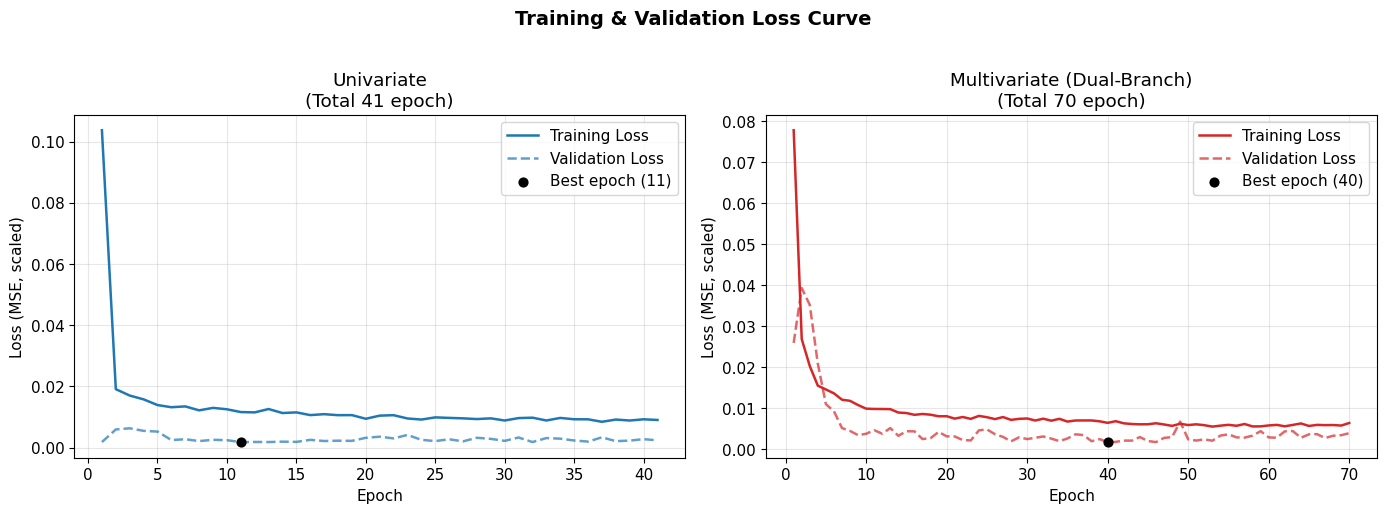

✓ 01_loss_curve.png


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, key, color) in zip(
    axes,
    [("Univariate", "univariate", "#1f77b4"), ("Multivariate (Dual-Branch)", "multivariate", "#d62728")]
):
    h = history[key]
    epochs = range(1, len(h['loss']) + 1)
    ax.plot(epochs, h['loss'],     label='Training Loss',   color=color, linewidth=1.8)
    ax.plot(epochs, h['val_loss'], label='Validation Loss', color=color, linewidth=1.8,
            linestyle='--', alpha=0.7)

    best_epoch = int(np.argmin(h['val_loss'])) + 1
    best_val   = min(h['val_loss'])
    ax.scatter([best_epoch], [best_val], color='black', zorder=5, s=40,
               label=f'Best epoch ({best_epoch})')

    ax.set_title(f'{name}\n(Total {len(h["loss"])} epoch)')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss (MSE, scaled)')
    ax.legend()

plt.suptitle('Training & Validation Loss Curve', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "01_loss_curve.png", bbox_inches='tight')
plt.show()
print("✓ 01_loss_curve.png")


## 3. Ablation Study `seq_monthly`

Studi ablasi ini menguji pengaruh panjang sekuens bulanan (`seq_monthly`) terhadap performa model multivariate, dengan kandidat 3, 6, dan 12 bulan. Setiap panel menampilkan satu metrik evaluasi (RMSE, MAPE, dan R²), dan batang dengan garis tepi tebal menandai konfigurasi terbaik pada metrik tersebut.

Cara membacanya: untuk RMSE dan MAPE semakin kecil semakin baik, sedangkan untuk R² semakin besar semakin baik. Nilai `seq_monthly=3` dipilih sebagai konfigurasi final karena menghasilkan RMSE terkecil.

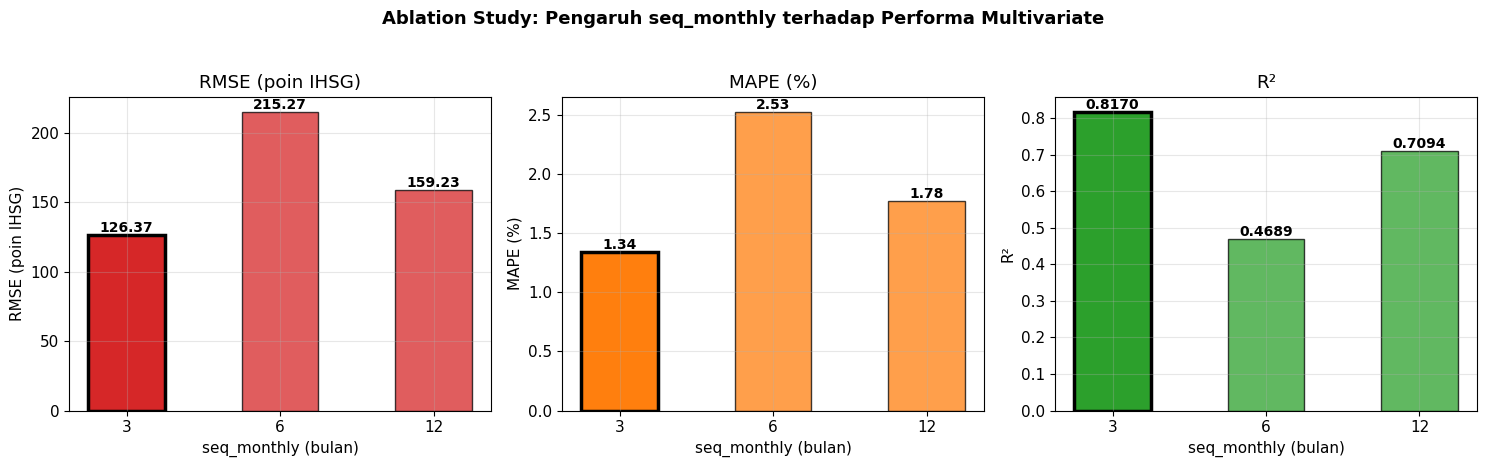

✓ 02_ablation_seq_monthly.png

Best seq_monthly: 3 (dipilih berdasarkan rmse (terkecil))


In [4]:
abl_df = pd.DataFrame(ablation['results'])
abl_df = abl_df.sort_values('seq_monthly').reset_index(drop=True)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

metrics_plot = [('rmse', 'RMSE (poin IHSG)', '#d62728'),
                ('mape', 'MAPE (%)', '#ff7f0e'),
                ('r2',   'R²', '#2ca02c')]

for ax, (metric, ylabel, color) in zip(axes, metrics_plot):
    bars = ax.bar(abl_df['seq_monthly'].astype(str), abl_df[metric],
                   color=color, alpha=0.75, edgecolor='black', width=0.5)

    best_idx = abl_df[metric].idxmin() if metric != 'r2' else abl_df[metric].idxmax()
    bars[best_idx].set_edgecolor('black')
    bars[best_idx].set_linewidth(2.5)
    bars[best_idx].set_alpha(1.0)

    for i, v in enumerate(abl_df[metric]):
        ax.text(i, v, f'{v:.4f}' if metric == 'r2' else f'{v:.2f}',
                ha='center', va='bottom', fontweight='bold', fontsize=10)

    ax.set_xlabel('seq_monthly (bulan)')
    ax.set_ylabel(ylabel)
    ax.set_title(ylabel)

plt.suptitle('Ablation Study: Pengaruh seq_monthly terhadap Performa Multivariate',
              fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig(FIG_DIR / "02_ablation_seq_monthly.png", bbox_inches='tight')
plt.show()

print("✓ 02_ablation_seq_monthly.png")
print(f"\nBest seq_monthly: {ablation['best_seq_monthly']} "
      f"(dipilih berdasarkan {ablation['selection_metric']})")


## 4. Actual vs Predicted — Univariate

Grafik deret waktu untuk seluruh periode uji yang membandingkan harga IHSG aktual (garis biru) dengan hasil prediksi model univariate (garis oranye putus-putus). Nilai RMSE, MAPE, dan R² ditampilkan pada judul sebagai ringkasan akurasi.

Cara membacanya: semakin rapat kedua garis mengikuti satu sama lain, semakin akurat prediksinya. Perhatikan bagian di mana prediksi tertinggal atau mendahului pergerakan aktual sebagai petunjuk keterbatasan model.

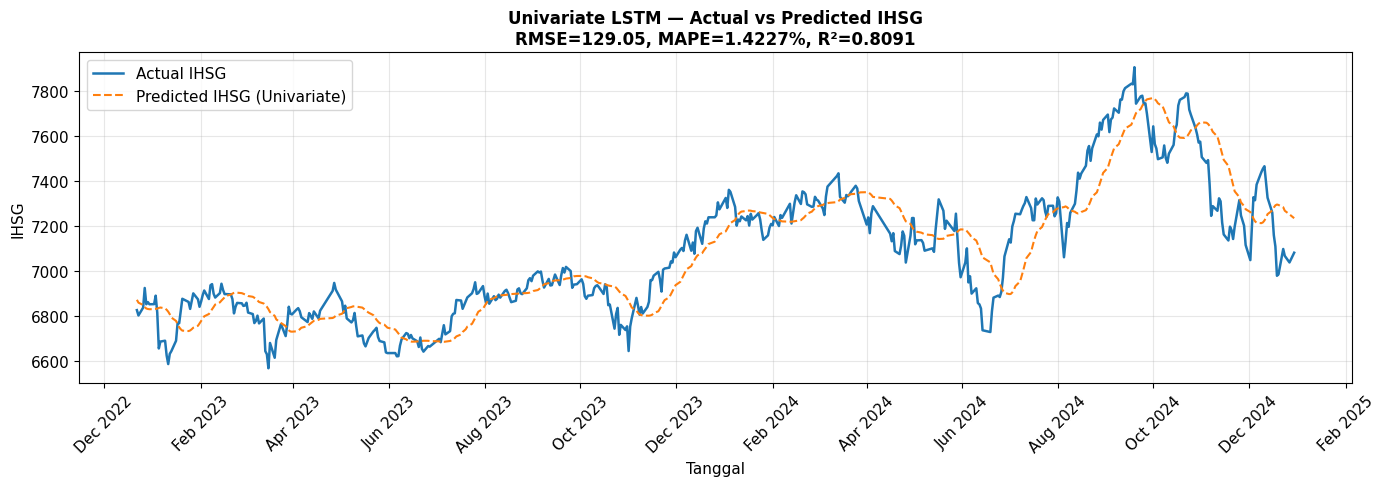

✓ 03_actual_vs_predicted_univariate.png


In [5]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(dates_uni, y_true_uni, label='Actual IHSG', color='#1f77b4', linewidth=1.8)
ax.plot(dates_uni, y_pred_uni, label='Predicted IHSG (Univariate)', color='#ff7f0e',
        linewidth=1.5, linestyle='--')

ax.set_title(f'Univariate LSTM — Actual vs Predicted IHSG\n'
             f'RMSE={model_config["univariate"]["test_metrics"]["rmse"]:.2f}, '
             f'MAPE={model_config["univariate"]["test_metrics"]["mape"]:.4f}%, '
             f'R²={model_config["univariate"]["test_metrics"]["r2"]:.4f}',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Tanggal')
ax.set_ylabel('IHSG')
ax.legend()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig(FIG_DIR / "03_actual_vs_predicted_univariate.png", bbox_inches='tight')
plt.show()
print("✓ 03_actual_vs_predicted_univariate.png")


## 5. Actual vs Predicted — Multivariate

Grafik yang sama untuk model multivariate (*dual-branch* LSTM), membandingkan IHSG aktual (garis biru) dengan prediksi model (garis merah putus-putus) di sepanjang periode uji. Judul mencantumkan RMSE, MAPE, dan R² sebagai pembanding langsung terhadap versi univariate di atas.

Cara membacanya: perhatikan seberapa dekat garis prediksi mengikuti garis aktual; prediksi yang lebih rapat dibanding model univariate mengindikasikan manfaat penambahan variabel makroekonomi.

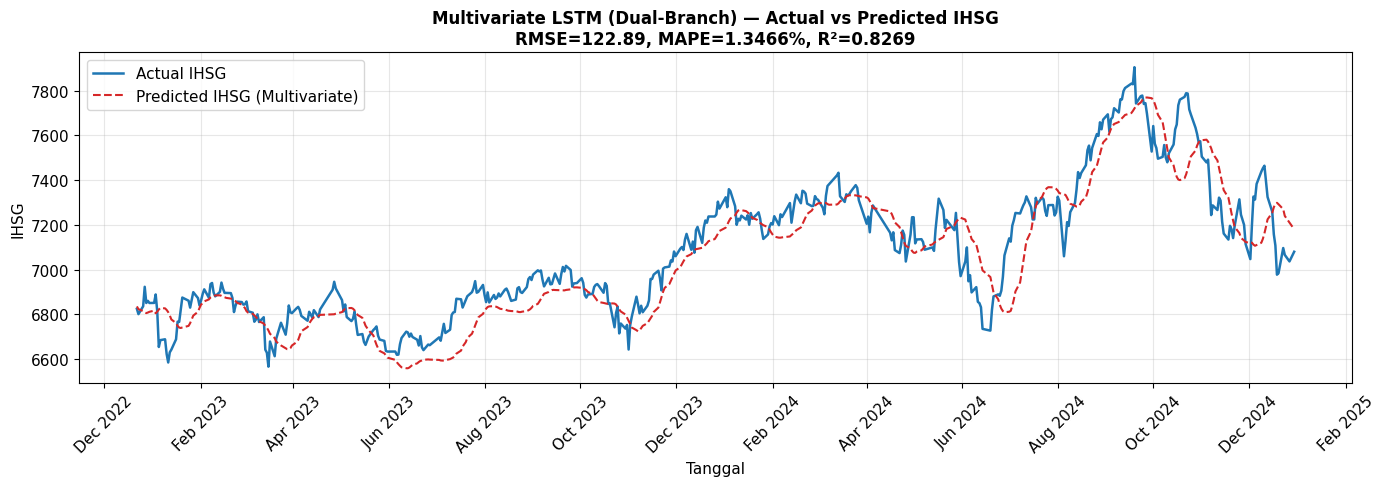

✓ 04_actual_vs_predicted_multivariate.png


In [6]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(dates_multi, y_true_multi, label='Actual IHSG', color='#1f77b4', linewidth=1.8)
ax.plot(dates_multi, y_pred_multi, label='Predicted IHSG (Multivariate)', color='#d62728',
        linewidth=1.5, linestyle='--')

ax.set_title(f'Multivariate LSTM (Dual-Branch) — Actual vs Predicted IHSG\n'
             f'RMSE={model_config["multivariate"]["test_metrics"]["rmse"]:.2f}, '
             f'MAPE={model_config["multivariate"]["test_metrics"]["mape"]:.4f}%, '
             f'R²={model_config["multivariate"]["test_metrics"]["r2"]:.4f}',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Tanggal')
ax.set_ylabel('IHSG')
ax.legend()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig(FIG_DIR / "04_actual_vs_predicted_multivariate.png", bbox_inches='tight')
plt.show()
print("✓ 04_actual_vs_predicted_multivariate.png")


## 6. Overlay Perbandingan — Univariate vs Multivariate vs Actual

Ketiga deret digabung dalam satu grafik: IHSG aktual (garis hitam) sebagai acuan, prediksi univariate (biru putus-putus), dan prediksi multivariate (merah putus-putus). Tujuannya agar selisih kedua model terhadap nilai aktual dapat dibandingkan langsung dalam satu tampilan.

Cara membacanya: garis prediksi yang lebih sering berimpit dengan garis hitam adalah model yang lebih akurat, terutama di titik balik (puncak dan lembah) pergerakan IHSG.

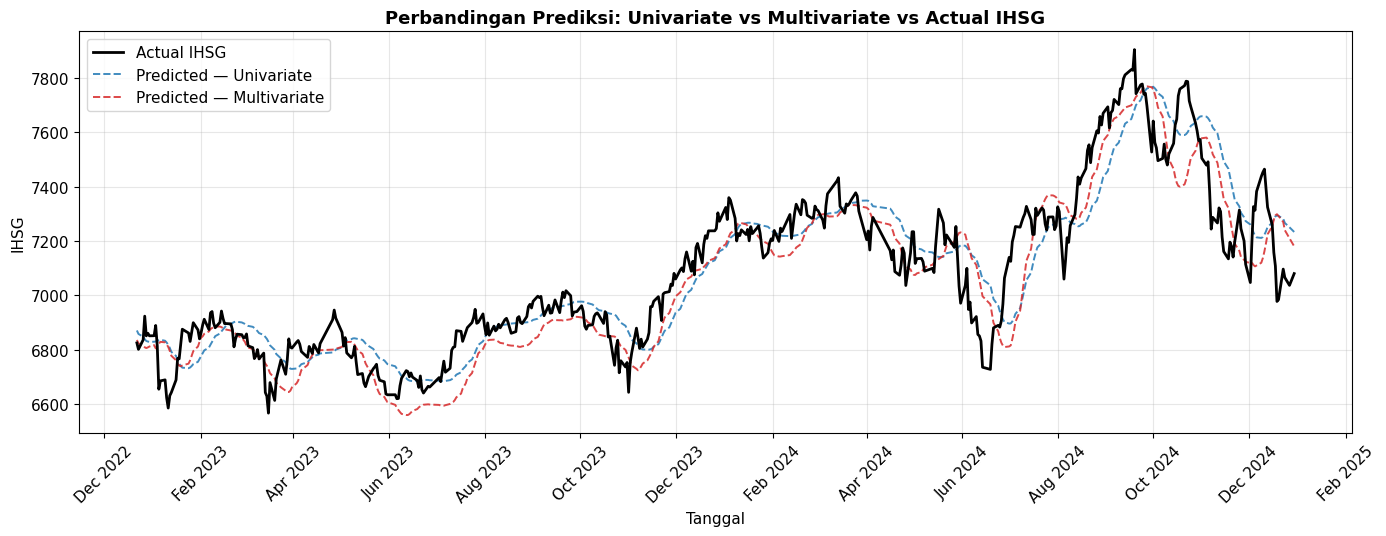

✓ 05_overlay_comparison.png


In [7]:
fig, ax = plt.subplots(figsize=(14, 5.5))

ax.plot(dates_multi, y_true_multi, label='Actual IHSG', color='black', linewidth=2.0, zorder=3)
ax.plot(dates_uni,   y_pred_uni,   label='Predicted — Univariate',  color='#1f77b4',
        linewidth=1.4, linestyle='--', alpha=0.85)
ax.plot(dates_multi, y_pred_multi, label='Predicted — Multivariate', color='#d62728',
        linewidth=1.4, linestyle='--', alpha=0.85)

ax.set_title('Perbandingan Prediksi: Univariate vs Multivariate vs Actual IHSG',
              fontsize=13, fontweight='bold')
ax.set_xlabel('Tanggal')
ax.set_ylabel('IHSG')
ax.legend()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig(FIG_DIR / "05_overlay_comparison.png", bbox_inches='tight')
plt.show()
print("✓ 05_overlay_comparison.png")


## 7. Residual Plot (Error sepanjang waktu)

Residual dihitung sebagai selisih Aktual − Prediksi untuk setiap titik waktu, ditampilkan pada dua panel terpisah (univariate di atas, multivariate di bawah) dengan garis acuan nol. Nilai rata-rata dan simpangan baku residual tercantum pada judul masing-masing panel.

Cara membacanya: residual yang ideal berfluktuasi acak di sekitar nol tanpa pola sistematis. Residual yang cenderung berada di satu sisi (selalu positif atau negatif) menandakan bias prediksi, sedangkan pola menanjak/menurun yang konsisten menunjukkan model gagal menangkap tren pada periode tersebut.

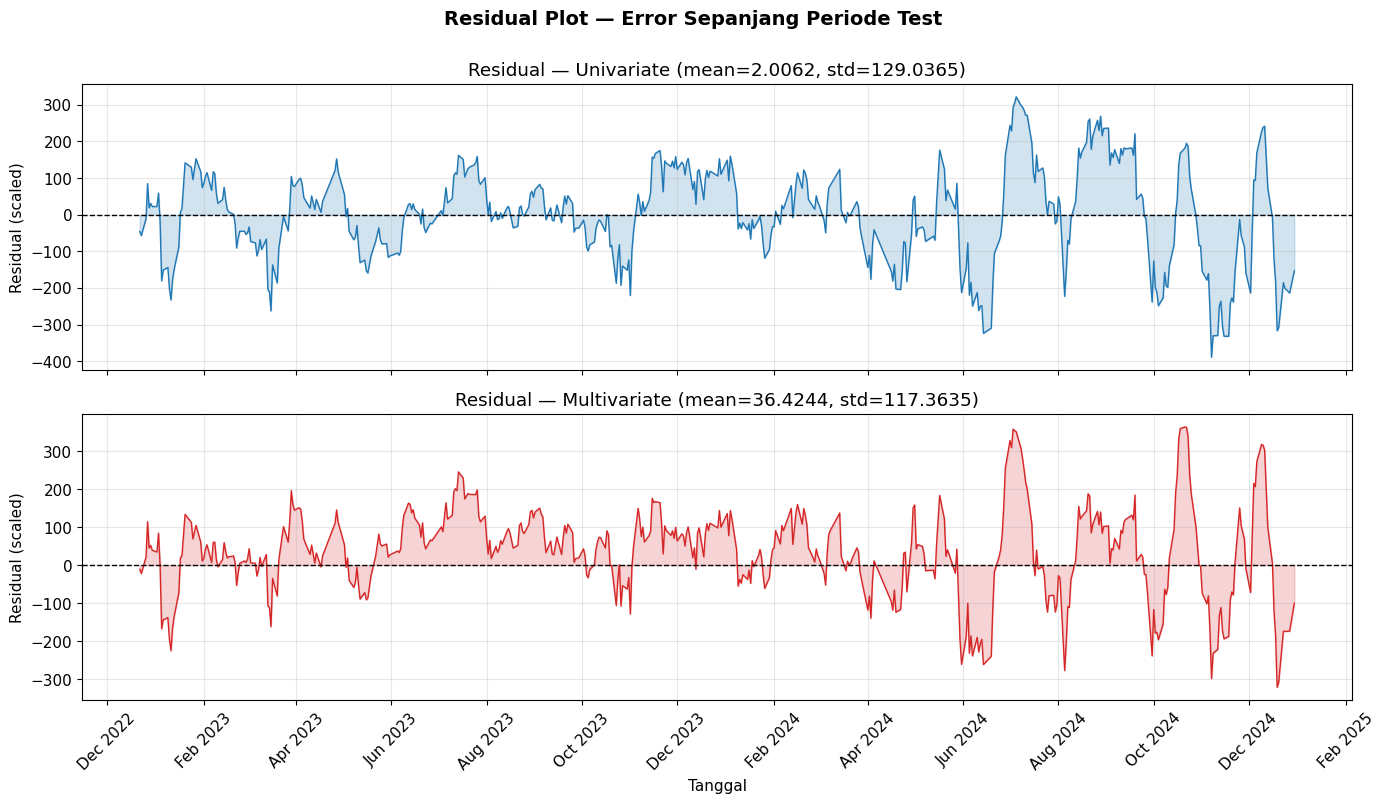

✓ 06_residual_plot.png


In [8]:
residual_uni   = y_true_uni - y_pred_uni
residual_multi = y_true_multi - y_pred_multi

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(dates_uni, residual_uni, color='#1f77b4', linewidth=1.0)
axes[0].axhline(0, color='black', linestyle='--', linewidth=1)
axes[0].fill_between(dates_uni, residual_uni, 0, alpha=0.2, color='#1f77b4')
axes[0].set_title(f'Residual — Univariate (mean={residual_uni.mean():.4f}, std={residual_uni.std():.4f})')
axes[0].set_ylabel('Residual (scaled)')

axes[1].plot(dates_multi, residual_multi, color='#d62728', linewidth=1.0)
axes[1].axhline(0, color='black', linestyle='--', linewidth=1)
axes[1].fill_between(dates_multi, residual_multi, 0, alpha=0.2, color='#d62728')
axes[1].set_title(f'Residual — Multivariate (mean={residual_multi.mean():.4f}, std={residual_multi.std():.4f})')
axes[1].set_ylabel('Residual (scaled)')
axes[1].set_xlabel('Tanggal')
axes[1].xaxis.set_major_locator(mdates.MonthLocator(interval=2))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.xticks(rotation=45)

plt.suptitle('Residual Plot — Error Sepanjang Periode Test', fontsize=14, fontweight='bold', y=1.0)
plt.tight_layout()
plt.savefig(FIG_DIR / "06_residual_plot.png", bbox_inches='tight')
plt.show()
print("✓ 06_residual_plot.png")


## 8. Distribusi Error (Histogram + KDE)

Histogram menunjukkan sebaran nilai residual untuk masing-masing model, dilengkapi kurva KDE (hitam) sebagai estimasi densitas dan kurva normal pembanding (hijau putus-putus) dengan rata-rata serta simpangan baku residual. Nilai *skewness* dan *kurtosis* dicetak di bawah grafik untuk mengukur kemiringan dan keruncingan distribusi.

Cara membacanya: distribusi yang terpusat dan simetris di sekitar nol menandakan error tidak bias (tidak cenderung konsisten melebihkan atau mengurangi prediksi). Semakin dekat bentuknya ke kurva normal pembanding, semakin baik perilaku error model.

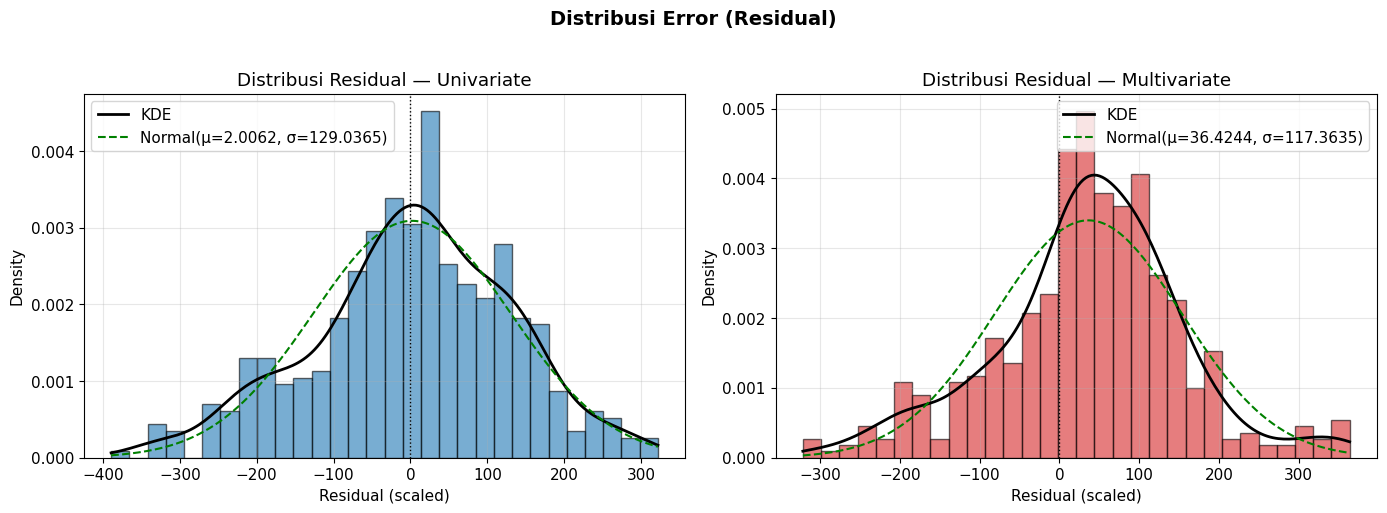

✓ 07_error_distribution.png

Skewness  — Univariate: -0.2584, Multivariate: -0.1628
Kurtosis  — Univariate: -0.0533, Multivariate: 0.7139


In [9]:
from scipy import stats

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, residual, color) in zip(
    axes,
    [("Univariate", residual_uni, "#1f77b4"), ("Multivariate", residual_multi, "#d62728")]
):
    ax.hist(residual, bins=30, density=True, alpha=0.6, color=color, edgecolor='black')

    # KDE overlay
    kde_x = np.linspace(residual.min(), residual.max(), 200)
    kde = stats.gaussian_kde(residual)
    ax.plot(kde_x, kde(kde_x), color='black', linewidth=2, label='KDE')

    # Normal distribution overlay untuk pembanding
    mu, sigma = residual.mean(), residual.std()
    norm_y = stats.norm.pdf(kde_x, mu, sigma)
    ax.plot(kde_x, norm_y, color='green', linewidth=1.5, linestyle='--',
            label=f'Normal(μ={mu:.4f}, σ={sigma:.4f})')

    ax.axvline(0, color='black', linestyle=':', linewidth=1)
    ax.set_title(f'Distribusi Residual — {name}')
    ax.set_xlabel('Residual (scaled)')
    ax.set_ylabel('Density')
    ax.legend()

plt.suptitle('Distribusi Error (Residual)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "07_error_distribution.png", bbox_inches='tight')
plt.show()
print("✓ 07_error_distribution.png")

print(f"\nSkewness  — Univariate: {stats.skew(residual_uni):.4f}, Multivariate: {stats.skew(residual_multi):.4f}")
print(f"Kurtosis  — Univariate: {stats.kurtosis(residual_uni):.4f}, Multivariate: {stats.kurtosis(residual_multi):.4f}")


## 9. Scatter Plot — Actual vs Predicted

Setiap titik mewakili satu hari uji, dengan nilai aktual pada sumbu-x dan nilai prediksi pada sumbu-y, disajikan untuk model univariate dan multivariate. Garis diagonal putus-putus (y = x) menandai prediksi sempurna, dan nilai R² dicantumkan pada judul tiap panel.

Cara membacanya: titik-titik yang rapat mengikuti garis diagonal menandakan prediksi akurat. Sebaran titik yang melebar dari garis menunjukkan error yang lebih besar, sementara titik yang sistematis berada di atas atau di bawah diagonal mengindikasikan kecenderungan melebihkan atau mengurangi prediksi.

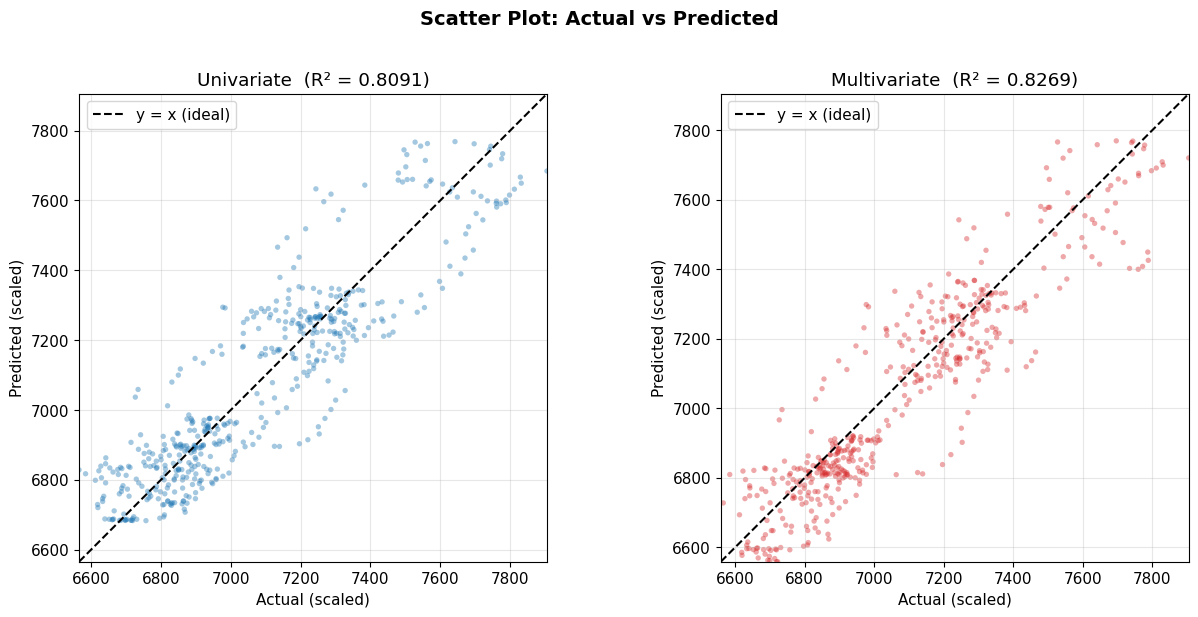

✓ 08_scatter_actual_vs_predicted.png


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))

for ax, (name, y_true, y_pred, color, r2) in zip(
    axes,
    [("Univariate", y_true_uni, y_pred_uni, "#1f77b4", model_config['univariate']['test_metrics']['r2']),
     ("Multivariate", y_true_multi, y_pred_multi, "#d62728", model_config['multivariate']['test_metrics']['r2'])]
):
    ax.scatter(y_true, y_pred, alpha=0.4, s=15, color=color, edgecolor='none')

    lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
    ax.plot(lims, lims, color='black', linestyle='--', linewidth=1.5, label='y = x (ideal)')

    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_aspect('equal')
    ax.set_xlabel('Actual (scaled)')
    ax.set_ylabel('Predicted (scaled)')
    ax.set_title(f'{name}  (R² = {r2:.4f})')
    ax.legend()

plt.suptitle('Scatter Plot: Actual vs Predicted', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "08_scatter_actual_vs_predicted.png", bbox_inches='tight')
plt.show()
print("✓ 08_scatter_actual_vs_predicted.png")


## 10. Tabel Perbandingan Metrik (Bar Chart)

Visualisasi batang yang merangkum tiga metrik evaluasi (RMSE, MAPE, dan R²) berdampingan untuk model univariate dan multivariate, dengan label nilai di atas tiap batang.

Cara membacanya: pada RMSE dan MAPE, batang yang lebih pendek lebih baik (error lebih kecil), sedangkan pada R² batang yang lebih tinggi lebih baik (variansi yang dijelaskan lebih besar).

          Univariate  Multivariate
RMSE        129.0521      122.8858
MAPE (%)      1.4227        1.3466
R²            0.8091        0.8269


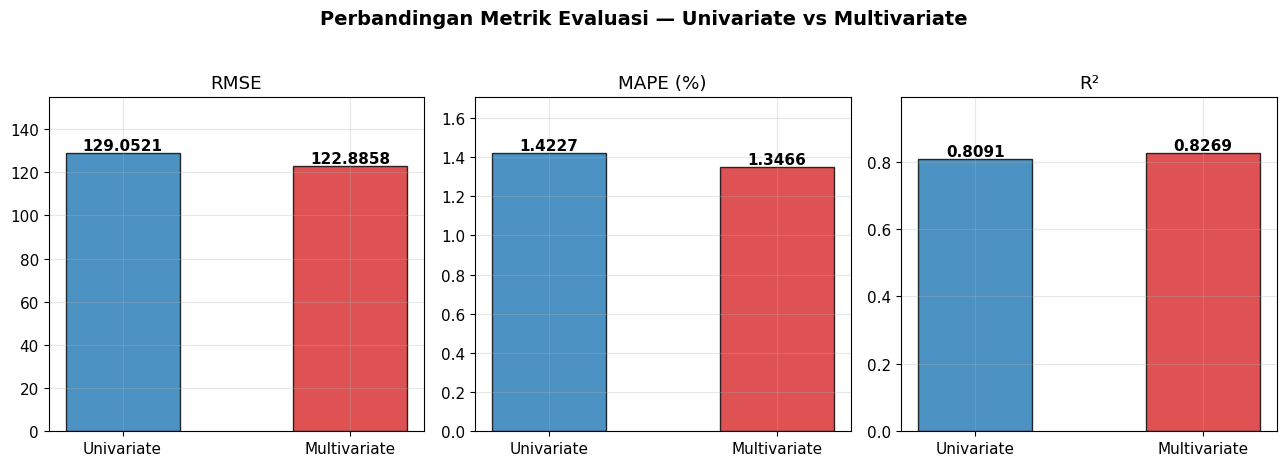

✓ 09_metric_comparison.png


In [11]:
metrics_compare = pd.DataFrame({
    'Univariate'  : [model_config['univariate']['test_metrics']['rmse'],
                     model_config['univariate']['test_metrics']['mape'],
                     model_config['univariate']['test_metrics']['r2']],
    'Multivariate': [model_config['multivariate']['test_metrics']['rmse'],
                     model_config['multivariate']['test_metrics']['mape'],
                     model_config['multivariate']['test_metrics']['r2']],
}, index=['RMSE', 'MAPE (%)', 'R²'])

print(metrics_compare)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))

for ax, metric in zip(axes, metrics_compare.index):
    vals   = metrics_compare.loc[metric]
    colors = ['#1f77b4', '#d62728']
    bars   = ax.bar(vals.index, vals.values, color=colors, alpha=0.8, edgecolor='black', width=0.5)

    for bar, v in zip(bars, vals.values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                f'{v:.4f}', ha='center', va='bottom', fontweight='bold')

    ax.set_title(metric)
    ax.set_ylim(0, max(vals.values) * 1.2)

plt.suptitle('Perbandingan Metrik Evaluasi — Univariate vs Multivariate',
              fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig(FIG_DIR / "09_metric_comparison.png", bbox_inches='tight')
plt.show()
print("✓ 09_metric_comparison.png")


## 12. Rolling MAPE (Error Relatif Berjalan)

Grafik ini menampilkan MAPE yang dihitung secara bergulir pada jendela 20 hari perdagangan (kurang lebih satu bulan) untuk kedua model, dilengkapi garis putus-putus mendatar sebagai acuan MAPE rata-rata keseluruhan masing-masing model.

Cara membacanya: kurva yang rendah dan stabil menandakan model konsisten akurat sepanjang waktu, sedangkan lonjakan menunjukkan periode ketika error membesar, misalnya saat IHSG bergerak di luar rentang data pelatihan. Posisi kurva multivariate yang umumnya di bawah kurva univariate menegaskan keunggulannya.

In [12]:
from sklearn.metrics import mean_squared_error, r2_score

def _subperiod_metrics(y_true, y_pred):
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    mape = float(np.mean(np.abs((y_true - y_pred) / y_true)) * 100)
    r2   = float(r2_score(y_true, y_pred))
    return rmse, mape, r2

# Subperiode: 2022-2023 (tahun != 2024) dan 2024 (tahun == 2024)
subperiods = [("2022-2023", lambda yr: yr != 2024), ("2024", lambda yr: yr == 2024)]

rows = []
for label, cond in subperiods:
    mask_uni   = np.array([cond(d.year) for d in dates_uni])
    mask_multi = np.array([cond(d.year) for d in dates_multi])
    for name, yt, yp, mask in [
        ("Univariate",   y_true_uni,   y_pred_uni,   mask_uni),
        ("Multivariate", y_true_multi, y_pred_multi, mask_multi),
    ]:
        rmse, mape, r2 = _subperiod_metrics(yt[mask], yp[mask])
        rows.append({"Subperiode": label, "Model": name, "n": int(mask.sum()),
                     "RMSE": round(rmse, 2), "MAPE (%)": round(mape, 4), "R2": round(r2, 4)})

subperiod_table = pd.DataFrame(rows)
print(subperiod_table.to_string(index=False))

subperiod_table.to_csv(FIG_DIR / "per_subperiode.csv", index=False)
print(f"\n✓ per_subperiode.csv → {FIG_DIR}")

Subperiode        Model   n   RMSE  MAPE (%)     R2
 2022-2023   Univariate 247  92.77    1.0947 0.5553
 2022-2023 Multivariate 247  94.75    1.1356 0.5361
      2024   Univariate 238 158.13    1.7631 0.5304
      2024 Multivariate 238 146.48    1.5656 0.5971

✓ per_subperiode.csv → D:\project_skripsi\reports\figures_v3


## 13. Zoom-in — 3 Bulan Terakhir Periode Test

Tampilan diperbesar pada 60 hari perdagangan terakhir (sekitar tiga bulan) yang memuat IHSG aktual beserta prediksi univariate dan multivariate, lengkap dengan penanda titik agar pergerakan harian terlihat jelas. Periode ini dipilih karena IHSG sempat bergerak di luar rentang data pelatihan (lihat pembahasan keterbatasan model).

Cara membacanya: perhatikan seberapa cepat tiap model mengikuti perubahan arah harga dari hari ke hari, serta apakah prediksi cenderung tertinggal (lag) terhadap pergerakan aktual.

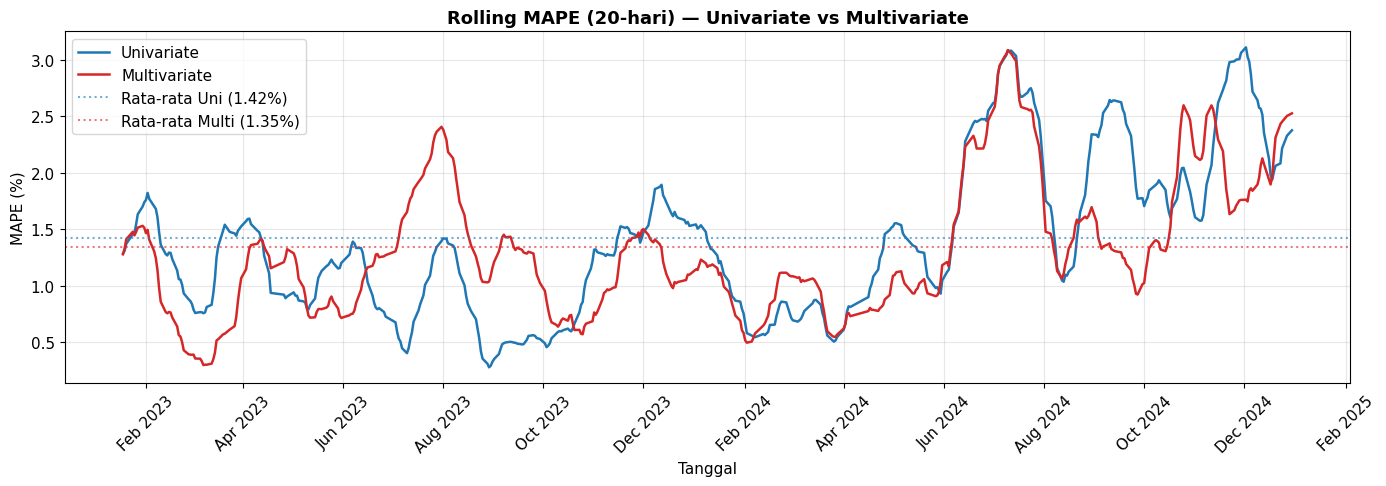

✓ 10_rolling_mape.png


In [13]:
WINDOW = 20  # rolling window ~1 bulan trading

ape_uni   = np.abs((y_true_uni - y_pred_uni) / (y_true_uni + 1e-8)) * 100
ape_multi = np.abs((y_true_multi - y_pred_multi) / (y_true_multi + 1e-8)) * 100

rolling_mape_uni   = pd.Series(ape_uni, index=dates_uni).rolling(WINDOW).mean()
rolling_mape_multi = pd.Series(ape_multi, index=dates_multi).rolling(WINDOW).mean()

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(rolling_mape_uni.index,   rolling_mape_uni.values,   label='Univariate',
        color='#1f77b4', linewidth=1.8)
ax.plot(rolling_mape_multi.index, rolling_mape_multi.values, label='Multivariate',
        color='#d62728', linewidth=1.8)

ax.axhline(model_config['univariate']['test_metrics']['mape'], color='#1f77b4',
           linestyle=':', alpha=0.6, label=f"Rata-rata Uni ({model_config['univariate']['test_metrics']['mape']:.2f}%)")
ax.axhline(model_config['multivariate']['test_metrics']['mape'], color='#d62728',
           linestyle=':', alpha=0.6, label=f"Rata-rata Multi ({model_config['multivariate']['test_metrics']['mape']:.2f}%)")

ax.set_title(f'Rolling MAPE ({WINDOW}-hari) — Univariate vs Multivariate',
              fontsize=13, fontweight='bold')
ax.set_xlabel('Tanggal')
ax.set_ylabel('MAPE (%)')
ax.legend()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig(FIG_DIR / "10_rolling_mape.png", bbox_inches='tight')
plt.show()
print("✓ 10_rolling_mape.png")


## 14. Ringkasan & Export Tabel

Sel ini menyusun tabel ringkasan akhir yang menggabungkan metrik evaluasi (RMSE, MAPE, R²) dan konfigurasi utama kedua model (jumlah *epoch* aktual, `seq_daily`, `seq_monthly`, serta `lstm_units`). Tabel disimpan ke `summary_table.csv` sehingga siap disalin ke dokumen skripsi, dan seluruh berkas gambar yang dihasilkan notebook ini ikut didaftar sebagai konfirmasi.

Cara membacanya: tabel ini merekap hasil seluruh grafik di atas dalam satu tampilan untuk perbandingan langsung antara model univariate dan multivariate.

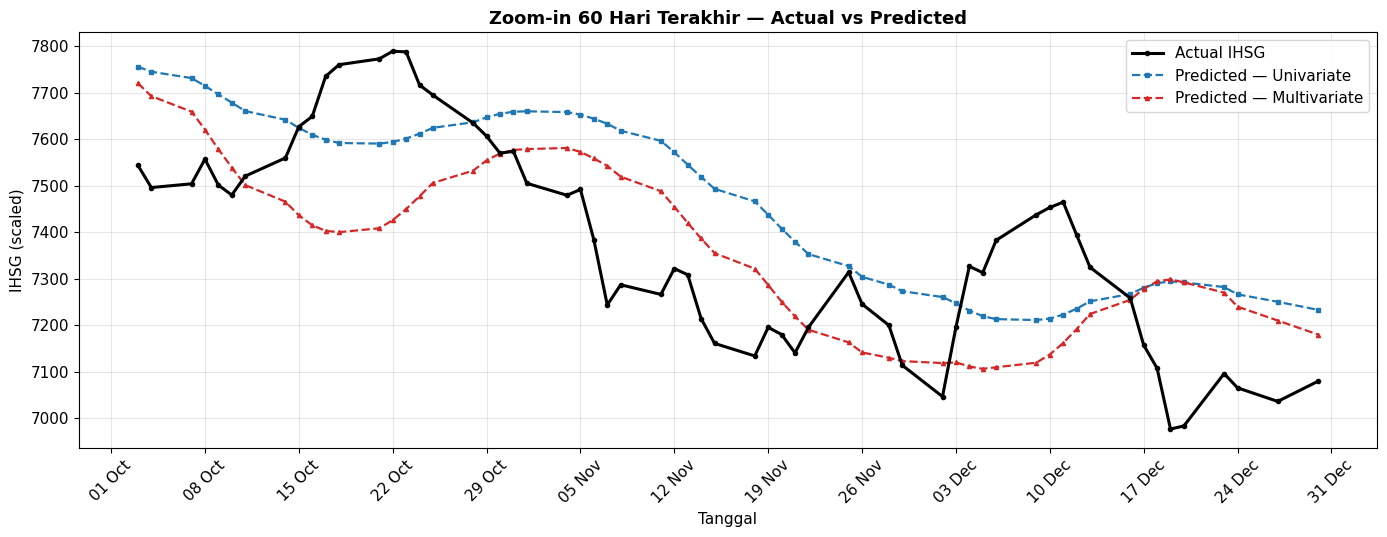

✓ 11_zoom_last_period.png


In [14]:
ZOOM_DAYS = 60  # ~3 bulan trading

zoom_dates_uni   = dates_uni[-ZOOM_DAYS:]
zoom_true_uni    = y_true_uni[-ZOOM_DAYS:]
zoom_pred_uni    = y_pred_uni[-ZOOM_DAYS:]

zoom_dates_multi = dates_multi[-ZOOM_DAYS:]
zoom_true_multi  = y_true_multi[-ZOOM_DAYS:]
zoom_pred_multi  = y_pred_multi[-ZOOM_DAYS:]

fig, ax = plt.subplots(figsize=(14, 5.5))

ax.plot(zoom_dates_multi, zoom_true_multi, label='Actual IHSG', color='black',
        linewidth=2.2, marker='o', markersize=3, zorder=3)
ax.plot(zoom_dates_uni,   zoom_pred_uni,   label='Predicted — Univariate',
        color='#1f77b4', linewidth=1.6, linestyle='--', marker='s', markersize=3)
ax.plot(zoom_dates_multi, zoom_pred_multi, label='Predicted — Multivariate',
        color='#d62728', linewidth=1.6, linestyle='--', marker='^', markersize=3)

ax.set_title(f'Zoom-in {ZOOM_DAYS} Hari Terakhir — Actual vs Predicted',
              fontsize=13, fontweight='bold')
ax.set_xlabel('Tanggal')
ax.set_ylabel('IHSG (scaled)')
ax.legend()
ax.xaxis.set_major_locator(mdates.WeekdayLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig(FIG_DIR / "11_zoom_last_period.png", bbox_inches='tight')
plt.show()
print("✓ 11_zoom_last_period.png")


## 13. Ringkasan & Export Tabel

Sel ini menyusun tabel ringkasan akhir yang menggabungkan metrik evaluasi (RMSE, MAPE, R²) dan konfigurasi utama kedua model (jumlah *epoch* aktual, `seq_daily`, `seq_monthly`, serta `lstm_units`). Tabel disimpan ke `summary_table.csv` sehingga siap disalin ke dokumen skripsi, dan seluruh berkas gambar yang dihasilkan notebook ini ikut didaftar sebagai konfirmasi.

Cara membacanya: tabel ini merekap hasil seluruh grafik di atas dalam satu tampilan untuk perbandingan langsung antara model univariate dan multivariate.

In [15]:
summary_table = pd.DataFrame({
    'Metrik'      : ['RMSE', 'MAPE (%)', 'R²', 'Epoch (aktual)', 'seq_daily', 'seq_monthly', 'lstm_units'],
    'Univariate'  : [
        f"{model_config['univariate']['test_metrics']['rmse']:.2f}",
        f"{model_config['univariate']['test_metrics']['mape']:.4f}",
        f"{model_config['univariate']['test_metrics']['r2']:.4f}",
        model_config['univariate']['epochs_ran'],
        model_config['univariate']['config']['seq_daily'],
        '-',
        model_config['univariate']['config']['lstm_units'],
    ],
    'Multivariate': [
        f"{model_config['multivariate']['test_metrics']['rmse']:.2f}",
        f"{model_config['multivariate']['test_metrics']['mape']:.4f}",
        f"{model_config['multivariate']['test_metrics']['r2']:.4f}",
        model_config['multivariate']['epochs_ran'],
        model_config['multivariate']['config']['seq_daily'],
        model_config['multivariate']['config']['seq_monthly'],
        model_config['multivariate']['config']['lstm_units'],
    ],
})

print(summary_table.to_string(index=False))

summary_table.to_csv(FIG_DIR / "summary_table.csv", index=False)
print(f"\n✓ summary_table.csv → {FIG_DIR}")

print("\n" + "=" * 60)
print("SEMUA GRAFIK TERSIMPAN DI:")
print(f"  {FIG_DIR}")
print("=" * 60)
for p in sorted(FIG_DIR.iterdir()):
    print(f"  {p.name}")


        Metrik Univariate Multivariate
          RMSE     129.05       122.89
      MAPE (%)     1.4227       1.3466
            R²     0.8091       0.8269
Epoch (aktual)         41           70
     seq_daily         90           90
   seq_monthly          -            3
    lstm_units        128          128

✓ summary_table.csv → D:\project_skripsi\reports\figures_v3

SEMUA GRAFIK TERSIMPAN DI:
  D:\project_skripsi\reports\figures_v3
  01_loss_curve.png
  02_ablation_seq_monthly.png
  03_actual_vs_predicted_univariate.png
  04_actual_vs_predicted_multivariate.png
  05_overlay_comparison.png
  06_residual_plot.png
  07_error_distribution.png
  08_scatter_actual_vs_predicted.png
  09_metric_comparison.png
  10_rolling_mape.png
  11_zoom_last_period.png
  arsitektur_dual_branch_lstm.png
  arsitektur_dual_branch_lstm_flowchart.png
  dm_test_result.csv
  eda_acf_pacf.png
  eda_adf.csv
  eda_correlation.csv
  eda_correlation.png
  eda_descriptive.csv
  eda_timeseries.png
  per_subperiode.